# LeetCode #421: Maximum XOR of Two Numbers in an Array

https://leetcode.com/problems/maximum-xor-of-two-numbers-in-an-array/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (All Pairs)** | $O(n^2)$ | $O(1)$ |
| **Optimal: Bitwise Trie ★** | $O(32n)$ | $O(32n)$ |

---

## Understanding the Methods

### Brute Force (All Pairs)
XOR every pair of numbers and keep track of the maximum. Simple but O(n^2).

### Optimal: Bitwise Trie ★
Build a trie of all numbers bit by bit (from the most significant bit). For each number, traverse the trie greedily choosing the opposite bit at each level to maximize XOR. Each number is processed in O(32) time.

**Why this is better than Brute Force:** The trie allows us to find the best XOR partner for each number in O(32) time, reducing overall complexity from O(n^2) to O(32n) = O(n).

**Constraints:**
* 1 <= nums.length <= 2 * 10^5
* 0 <= nums[i] <= 2^31 - 1

## Solutions

### C#

In [ ]:
public class Solution {
    public int FindMaximumXOR(int[] nums) {
        int maxXor = 0, mask = 0;
        for (int i = 31; i >= 0; i--) {
            mask |= (1 << i);
            var prefixes = new HashSet<int>();
            foreach (int n in nums)
                prefixes.Add(n & mask);
            int candidate = maxXor | (1 << i);
            foreach (int p in prefixes) {
                if (prefixes.Contains(candidate ^ p)) {
                    maxXor = candidate;
                    break;
                }
            }
        }
        return maxXor;
    }
}

### Python

In [ ]:
class Solution:
    def findMaximumXOR(self, nums: list[int]) -> int:
        max_xor = 0
        mask = 0
        for i in range(31, -1, -1):
            mask |= (1 << i)
            prefixes = {n & mask for n in nums}
            candidate = max_xor | (1 << i)
            for p in prefixes:
                if candidate ^ p in prefixes:
                    max_xor = candidate
                    break
        return max_xor

### Go

In [ ]:
func findMaximumXOR(nums []int) int {
    maxXor, mask := 0, 0
    for i := 31; i >= 0; i-- {
        mask |= 1 << i
        prefixes := map[int]bool{}
        for _, n := range nums {
            prefixes[n&mask] = true
        }
        candidate := maxXor | (1 << i)
        for p := range prefixes {
            if prefixes[candidate^p] {
                maxXor = candidate
                break
            }
        }
    }
    return maxXor
}

### Rust

In [ ]:
use std::collections::HashSet;

impl Solution {
    pub fn find_maximum_xor(nums: Vec<i32>) -> i32 {
        let mut max_xor = 0i32;
        let mut mask = 0i32;
        for i in (0..=31).rev() {
            mask |= 1 << i;
            let prefixes: HashSet<i32> = nums.iter().map(|&n| n & mask).collect();
            let candidate = max_xor | (1 << i);
            for &p in &prefixes {
                if prefixes.contains(&(candidate ^ p)) {
                    max_xor = candidate;
                    break;
                }
            }
        }
        max_xor
    }
}

## Example Scenarios

### 1. Common Case — Greedy Opposite-Bit Descent

**Input:** `nums = [3,10,5,25,2,8]`

Insert all six numbers into a 5-bit trie, then query $25 = 11001_2$: at each level take the *opposite* branch if it exists (bits $0,0,1$), falling back to the same bit when it does not. The descent lands on $5 = 00101_2$, giving $25 \oplus 5 = 28$. **Output:** `28`

### 2. Slightly Complex — Winner Is Not the Widest Spread

**Input:** `nums = [9,5,12,2]`

The naive guess $12 \oplus 9 = 5$ (the two largest) is wrong; greedy descent pairs $12 = 1100_2$ with $2 = 0010_2$ for $1110_2 = 14$. Each query costs $O(B)$ with $B = 32$, so the whole scan is $O(32n)$. **Output:** `14`

### 3. Edge Case: Time Factor — Long Shared Prefix, Tiny Answer

**Input:** `nums = [16,17,18,19]`

All four numbers share the prefix $100$, so the top levels offer no opposite branch and contribute nothing. The algorithm still walks all $32$ levels for every number — $O(32n)$ work for an answer of just $19 \oplus 16 = 3$. **Output:** `3`

### 4. Edge Case: Space Factor — Fully Branching Trie

**Input:** `nums = [0,1,2,3,4,5,6,7]`

Every 3-bit pattern is present, so the trie is a *complete* binary tree — the $O(32n)$ node ceiling in the general case. Every level offers an opposite branch, so $7 \oplus 0 = 7$ needs no fallback. **Output:** `7`

### 5. Almost-Impossible but Plausible — Full 31-Bit Spread

**Input:** `nums = [0, 2147483647]`

The two constraint extremes, $0$ and $2^{31} - 1$. Their XOR sets every one of the 31 low bits, hitting the largest answer possible, $2147483647 \approx 2.1 \times 10^9$ — still inside signed 32-bit range, so no overflow guard is needed. **Output:** `2147483647`


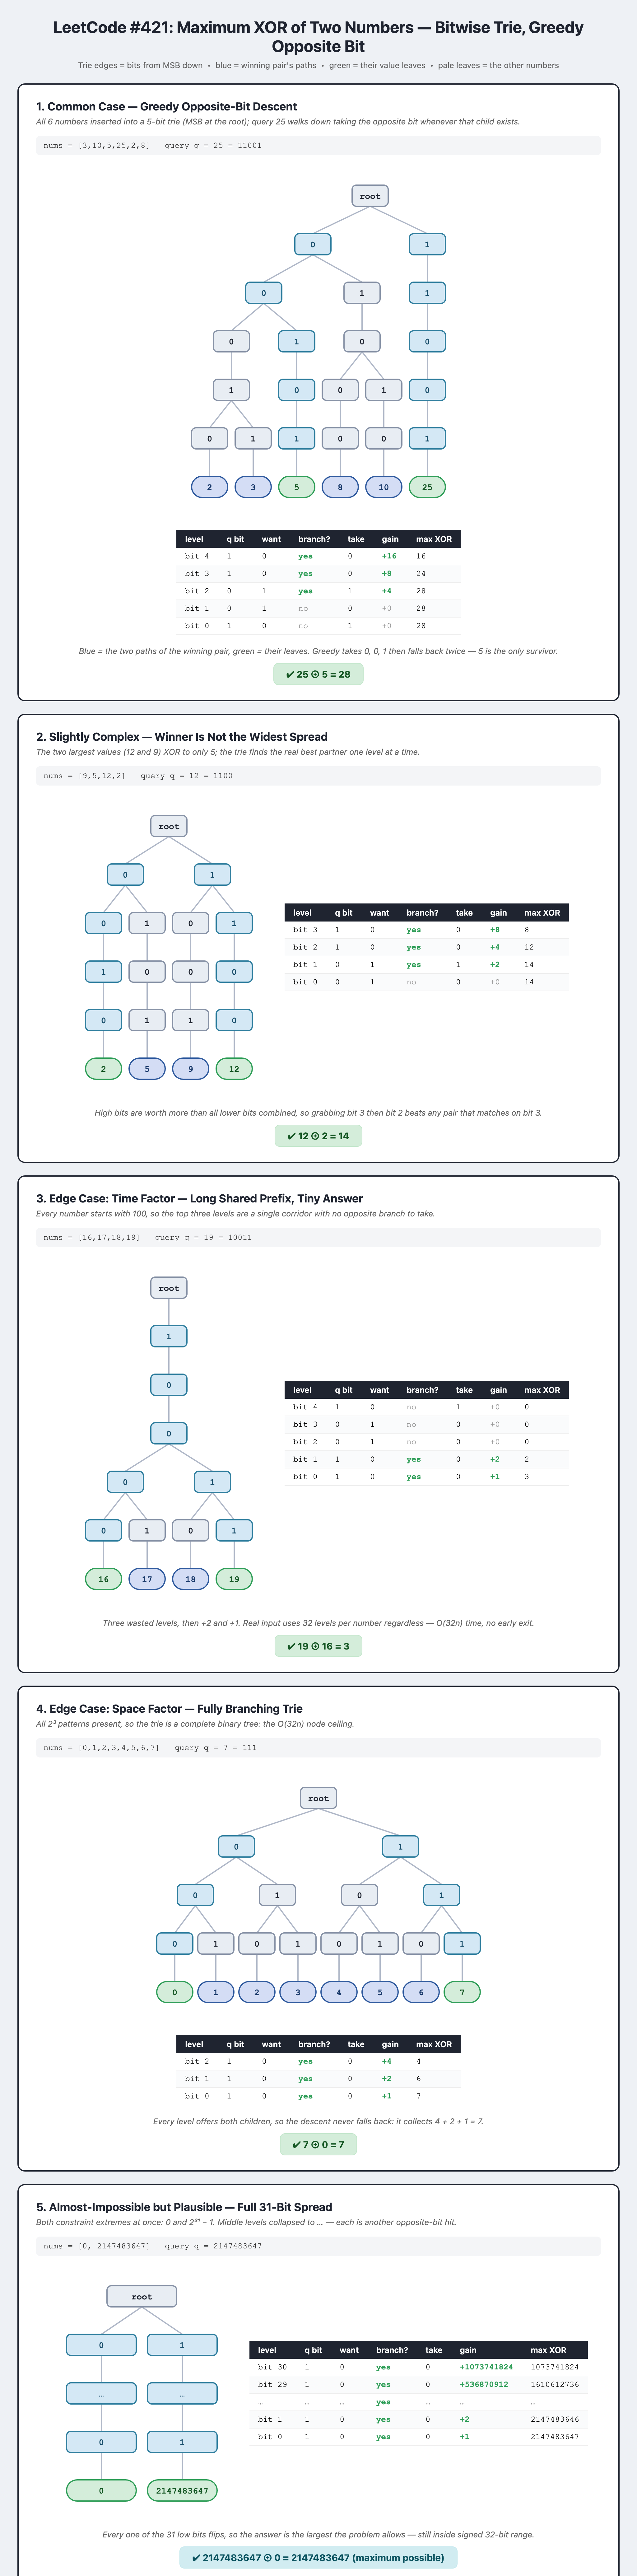